# Claims desk · Supervisor kickstart

**Factored technical workshop - Agentic workflows**

One agent with every job in a single prompt gets unreliable. A **supervisor** reads the case and sends it to a narrow specialist, then decides again.

This notebook builds the middle of a fictional auto-claims desk. Run it from top to bottom. It does not approve, deny, or pay a claim. The numbers are synthetic.

The rest of this repository is the full desk: document reading, tool-calling specialists, and a page that advances one step at a time.


### What you'll build

- Two specialist nodes, **coverage** and **damage**. Each one is a plain Python function.
- A **supervisor** that chooses the next step with a structured decision.
- A graph where each specialist reports back until the supervisor finishes.
- An **adjuster** pause when the repair estimate meets the policy threshold.


---
## Setup

On Colab, the next cell installs the libraries this notebook uses. Locally, run `uv sync` inside `notebooks/` and select that environment as the kernel. Leave the install cell skipped.

The cell reads `OPENROUTER_API_KEY` from the project `.env` when you run it from this folder or the repository root. On Colab it asks for the key. The key stays in memory for this session and is not written into the notebook.


In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "langgraph>=1.0,<2" "openai>=2,<3" "pydantic>=2,<3"


In [2]:
import json
import operator
import os
import uuid
from pathlib import Path
from typing import Annotated, Literal, TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt
from openai import OpenAI
from pydantic import BaseModel, ConfigDict

MODEL = "qwen/qwen3.5-flash-02-23"


def load_api_key() -> str:
    for path in (Path.cwd() / ".env", Path.cwd().parent / ".env"):
        if not path.is_file():
            continue
        for raw in path.read_text(encoding="utf-8").splitlines():
            line = raw.strip()
            if not line or line.startswith("#") or "=" not in line:
                continue
            name, value = line.split("=", 1)
            if name.strip() == "OPENROUTER_API_KEY" and value.strip():
                os.environ.setdefault(
                    "OPENROUTER_API_KEY",
                    value.strip().strip('"').strip("'"),
                )
    key = os.environ.get("OPENROUTER_API_KEY", "").strip()
    if not key:
        from getpass import getpass

        key = getpass("OPENROUTER_API_KEY: ").strip()
        os.environ["OPENROUTER_API_KEY"] = key
    if not key:
        raise RuntimeError(
            "Set OPENROUTER_API_KEY in the environment or in the project .env."
        )
    return key


client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=load_api_key(),
    timeout=60.0,
)
print("Client ready.", MODEL)


Client ready. qwen/qwen3.5-flash-02-23


---
## Step 1 · Two claims and two specialists

Each specialist does one job and returns a finding. The data is canned, so this part does not depend on a model.

- **AUTO-202** is a localized side repair. The ratio stays under the threshold.
- **AUTO-101** is a front impact. The ratio meets the threshold, so a person has to look.


In [3]:
CASES = {
    "AUTO-202": {
        "vehicle": "Toyota Corolla 2019",
        "repair_estimate_brl": 18_000,
        "reference_value_brl": 80_000,
        "total_loss_threshold": 0.80,
    },
    "AUTO-101": {
        "vehicle": "Honda Civic 2020",
        "repair_estimate_brl": 82_000,
        "reference_value_brl": 100_000,
        "total_loss_threshold": 0.75,
    },
}


def brl(amount: float) -> str:
    return f"BRL {amount:,.0f}"


def pct(value: float) -> str:
    return f"{value:.1%}".replace(".0%", "%")


def loss_ratio(findings: dict) -> float:
    repair = findings["damage"]["repair_estimate_brl"]
    reference = findings["coverage"]["reference_value_brl"]
    return repair / reference


class State(TypedDict):
    case_id: str
    findings: dict
    next_agent: str
    trace: Annotated[list[str], operator.add]


def coverage(state: State):
    case = CASES[state["case_id"]]
    finding = {
        "collision_covered": True,
        "reference_value_brl": case["reference_value_brl"],
        "total_loss_threshold": case["total_loss_threshold"],
    }
    findings = dict(state["findings"])
    findings["coverage"] = finding
    return {
        "findings": findings,
        "trace": [
            f"Coverage: {case['vehicle']}, reference {brl(finding['reference_value_brl'])}, "
            f"threshold {pct(finding['total_loss_threshold'])}."
        ],
    }


def damage(state: State):
    case = CASES[state["case_id"]]
    finding = {"repair_estimate_brl": case["repair_estimate_brl"]}
    findings = dict(state["findings"])
    findings["damage"] = finding
    return {
        "findings": findings,
        "trace": [f"Damage: repair estimate {brl(finding['repair_estimate_brl'])}."],
    }


---
## Step 2 · The supervisor

The supervisor is the only model call. It returns `coverage`, `damage`, `adjuster`, or `FINISH`.

A short policy then protects the route. Coverage and damage both have to happen before the end. The adjuster is required when the loss ratio meets the threshold, and only once. If the model already chose that route, the policy leaves it alone.


In [4]:
class Route(BaseModel):
    model_config = ConfigDict(extra="forbid")
    next_agent: Literal["coverage", "damage", "adjuster", "FINISH"]
    reason: str


SUPERVISOR_PROMPT = (
    "You are an insurer claims investigation supervisor, not a consumer assistant. "
    "Choose the next step: coverage, damage, adjuster, or FINISH. "
    "Coverage and damage must both be present before FINISH or adjuster. "
    "Call adjuster only after both findings exist, and only when loss_ratio meets "
    "total_loss_threshold. If findings.adjuster is already present, choose FINISH. "
    "Below the threshold, FINISH once both findings exist. "
    "Do not approve or deny the claim. "
    "Return one JSON object with keys next_agent and reason."
)


def parse_object(text: str) -> dict:
    text = (text or "").strip()
    if text.startswith("```"):
        text = text.strip("`")
        text = text.removeprefix("json").strip()
    start, end = text.find("{"), text.rfind("}")
    if start < 0 or end <= start:
        raise ValueError("The model did not return a JSON object.")
    data = json.loads(text[start : end + 1])
    if not isinstance(data, dict):
        raise ValueError("Structured output was not a JSON object.")
    return data


def ask_route(payload: str) -> Route:
    schema = Route.model_json_schema()
    messages = [
        {"role": "system", "content": SUPERVISOR_PROMPT},
        {"role": "user", "content": payload},
    ]
    last_error: Exception | None = None
    for _attempt in range(2):
        completion = client.chat.completions.create(
            model=MODEL,
            temperature=0,
            messages=messages,
            response_format={
                "type": "json_schema",
                "json_schema": {"name": "Route", "strict": True, "schema": schema},
            },
            extra_body={"reasoning": {"enabled": False}},
        )
        content = completion.choices[0].message.content or ""
        try:
            return Route.model_validate(parse_object(content))
        except Exception as exc:
            last_error = exc
            messages = messages + [
                {"role": "assistant", "content": content},
                {
                    "role": "user",
                    "content": f"That was not a valid route: {exc}. Return only the JSON object.",
                },
            ]
    raise RuntimeError(f"Supervisor route failed: {last_error}") from last_error


def apply_policy(state: State, proposed: str) -> str:
    findings = state["findings"]
    if "coverage" not in findings:
        return "coverage"
    if "damage" not in findings:
        return "damage"
    if "adjuster" in findings:
        return "FINISH"
    if loss_ratio(findings) >= findings["coverage"]["total_loss_threshold"]:
        return "adjuster"
    return "FINISH"


def supervisor(state: State):
    summary = {"case_id": state["case_id"], "findings": state["findings"]}
    if "coverage" in state["findings"] and "damage" in state["findings"]:
        summary["loss_ratio"] = round(loss_ratio(state["findings"]), 4)
    proposed = ask_route(json.dumps(summary, ensure_ascii=False))
    chosen = apply_policy(state, proposed.next_agent)
    reason = " ".join(proposed.reason.split())
    if len(reason) > 180:
        reason = reason[:177] + "..."
    if chosen == proposed.next_agent:
        line = f"Supervisor -> {chosen}: {reason}"
    else:
        line = (
            f"Supervisor -> {chosen}: policy moved the route off {proposed.next_agent}."
        )
    return {"next_agent": chosen, "trace": [line]}


---
## Step 3 · The adjuster pause

`interrupt` stops the graph and hands a packet to a person. Resuming writes their choice onto the case. The repair estimate, the reference value, and the ratio stay as they were.


In [5]:
CHOICES = {
    "total_loss": "Review as total loss",
    "repair": "Review as repair",
}


def adjuster(state: State):
    findings = state["findings"]
    ratio = loss_ratio(findings)
    packet = {
        "repair_estimate_brl": findings["damage"]["repair_estimate_brl"],
        "reference_value_brl": findings["coverage"]["reference_value_brl"],
        "loss_ratio": round(ratio, 4),
        "total_loss_threshold": findings["coverage"]["total_loss_threshold"],
        "message": "Choose total_loss or repair. The choice is recorded and does not change the numbers.",
    }
    answer = interrupt(packet)
    if not isinstance(answer, dict):
        raise ValueError(
            'Resume with {"choice": "total_loss"} or {"choice": "repair"}.'
        )
    choice = str(answer.get("choice") or "")
    label = CHOICES.get(choice)
    if not label:
        raise ValueError("choice must be total_loss or repair.")
    updated = dict(findings)
    updated["adjuster"] = {"choice": choice, "label": label}
    return {"findings": updated, "trace": [f"Adjuster: {label}."]}


---
## Step 4 · Wire the graph

`START` goes to the supervisor. A conditional edge sends the case to the chosen node, or ends. Coverage, damage, and the adjuster each come back to the supervisor.


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	coverage(coverage)
	damage(damage)
	adjuster(adjuster)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	adjuster --> supervisor;
	coverage --> supervisor;
	damage --> supervisor;
	supervisor -. &nbsp;FINISH&nbsp; .-> __end__;
	supervisor -.-> adjuster;
	supervisor -.-> coverage;
	supervisor -.-> damage;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



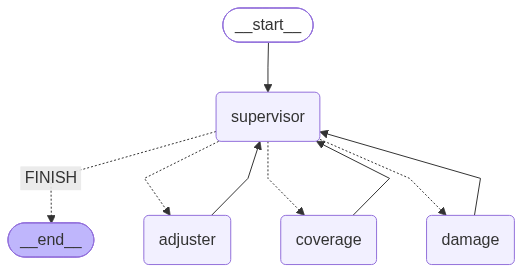

In [6]:
builder = StateGraph(State)
builder.add_node("supervisor", supervisor)
builder.add_node("coverage", coverage)
builder.add_node("damage", damage)
builder.add_node("adjuster", adjuster)
builder.add_edge(START, "supervisor")
builder.add_conditional_edges(
    "supervisor",
    lambda state: state["next_agent"],
    {"coverage": "coverage", "damage": "damage", "adjuster": "adjuster", "FINISH": END},
)
for name in ("coverage", "damage", "adjuster"):
    builder.add_edge(name, "supervisor")

desk = builder.compile(checkpointer=InMemorySaver())
THREADS: dict[str, str] = {}

print(desk.get_graph().draw_mermaid())
try:
    from IPython.display import Image, display

    display(Image(desk.get_graph().draw_mermaid_png()))
except Exception as exc:
    print(
        "The mermaid text above is the graph. Image render skipped:", type(exc).__name__
    )


def _config(case_id: str) -> dict:
    return {"configurable": {"thread_id": THREADS[case_id]}, "recursion_limit": 15}


def run(case_id: str):
    THREADS[case_id] = f"{case_id}-{uuid.uuid4().hex[:8]}"
    desk.invoke(
        {"case_id": case_id, "findings": {}, "trace": [], "next_agent": ""},
        _config(case_id),
    )
    return desk.get_state(_config(case_id))


def resume(case_id: str, choice: str):
    desk.invoke(Command(resume={"choice": choice}), _config(case_id))
    return desk.get_state(_config(case_id))


def show(snapshot):
    for line in snapshot.values.get("trace") or []:
        print(line)
    pending = [
        item.value
        for task in snapshot.tasks
        for item in (getattr(task, "interrupts", ()) or ())
    ]
    if pending:
        packet = pending[0]
        print("---")
        print("Paused for an adjuster.")
        print(
            f"Repair {brl(packet['repair_estimate_brl'])} · "
            f"reference {brl(packet['reference_value_brl'])}"
        )
        print(
            f"Loss ratio {pct(packet['loss_ratio'])} · "
            f"threshold {pct(packet['total_loss_threshold'])}"
        )
        print(packet["message"])
        return
    if snapshot.next:
        print("Still running:", ", ".join(snapshot.next))
        return
    findings = snapshot.values["findings"]
    print("---")
    print(f"Finished. Loss ratio {pct(loss_ratio(findings))}.")
    print(f"Repair estimate {brl(findings['damage']['repair_estimate_brl'])}.")
    if "adjuster" in findings:
        print(f"Adjuster consult: {findings['adjuster']['label']}.")


---
## Step 5 · A repair that can finish

AUTO-202 visits coverage and damage, then finishes. No person is asked. The loss ratio is 22.5%.


In [7]:
show(run("AUTO-202"))


Supervisor -> coverage: No findings exist yet. Coverage investigation must be initiated first to gather necessary information before proceeding to damage assessment or other steps.
Coverage: Toyota Corolla 2019, reference BRL 80,000, threshold 80%.
Supervisor -> damage: Coverage findings are present, but damage assessment is missing. Both coverage and damage findings are required before proceeding to adjuster or finishing the case.
Damage: repair estimate BRL 18,000.
Supervisor -> FINISH: Both coverage and damage findings are present. The loss ratio (0.225) is below the total_loss_threshold (0.8), so no adjuster call is required.
---
Finished. Loss ratio 22.5%.
Repair estimate BRL 18,000.


---
## Step 6 · A ratio that needs a person

AUTO-101 visits the same two specialists. The ratio is 82%, above the 75% threshold, so the graph pauses inside the adjuster node.

The following cell resumes with **Review as total loss**. Run that cell again with `repair` to record the other choice. The estimate stays BRL 82,000 either way.


In [8]:
show(run("AUTO-101"))


Supervisor -> coverage: No findings exist yet; must first determine coverage status before proceeding to damage assessment or other steps.
Coverage: Honda Civic 2020, reference BRL 100,000, threshold 75%.
Supervisor -> damage: Coverage findings are present, but damage assessment is missing. Both coverage and damage findings are required before proceeding to adjuster or finishing the case.
Damage: repair estimate BRL 82,000.
Supervisor -> adjuster: Both coverage and damage findings are present. The loss ratio (0.82) exceeds the total_loss_threshold (0.75), triggering the requirement to call an adjuster.
---
Paused for an adjuster.
Repair BRL 82,000 · reference BRL 100,000
Loss ratio 82% · threshold 75%
Choose total_loss or repair. The choice is recorded and does not change the numbers.


In [9]:
show(resume("AUTO-101", "total_loss"))


Supervisor -> coverage: No findings exist yet; must first determine coverage status before proceeding to damage assessment or other steps.
Coverage: Honda Civic 2020, reference BRL 100,000, threshold 75%.
Supervisor -> damage: Coverage findings are present, but damage assessment is missing. Both coverage and damage findings are required before proceeding to adjuster or finishing the case.
Damage: repair estimate BRL 82,000.
Supervisor -> adjuster: Both coverage and damage findings are present. The loss ratio (0.82) exceeds the total_loss_threshold (0.75), triggering the requirement to call an adjuster.
Adjuster: Review as total loss.
Supervisor -> FINISH: The adjuster finding is already present in the case data, which triggers the FINISH step according to the protocol.
---
Finished. Loss ratio 82%.
Repair estimate BRL 82,000.
Adjuster consult: Review as total loss.


---
## When to stop adding agents

Split a job when one prompt is juggling too many tools. Leave a step as ordinary code when it always happens the same way. Reading the claim document, in the full desk, is that kind of step. The supervisor does not decide whether to read it.

## Key takeaways

- A supervisor is shared state plus a routing decision.
- The specialists in this notebook are functions. In the full desk they become agents with tools.
- The adjuster is a human interrupt. The choice is recorded. The calculated ratio does not move.
- A recommendation here is preliminary. It does not authorize payment.

The full step-through desk is the rest of this repository: https://github.com/WittmannF/factored-workshop-agentic-workflows
